In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Environment is ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Environment is ready!
Pandas: 3.0.5
NumPy: 2.5.2
Scikit-learn: 1.9.0


In [5]:
import pandas as pd

df = pd.read_csv("../data/Social_Network_Ads.csv")

df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [6]:
import pandas as pd

df = pd.read_csv("../data/Social_Network_Ads.csv")

df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [7]:
df.shape


(400, 3)

In [8]:
df.columns

Index(['Age', 'EstimatedSalary', 'Purchased'], dtype='str')

df.info()

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [10]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


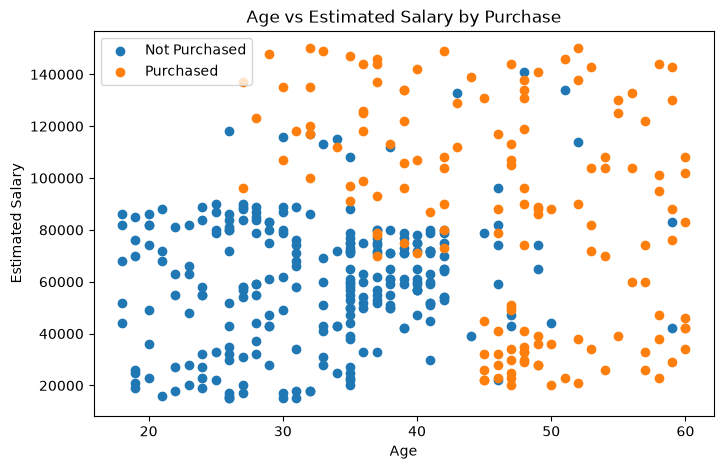

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df[df["Purchased"] == 0]["Age"],
    df[df["Purchased"] == 0]["EstimatedSalary"],
    label="Not Purchased"
)

plt.scatter(
    df[df["Purchased"] == 1]["Age"],
    df[df["Purchased"] == 1]["EstimatedSalary"],
    label="Purchased"
)

plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.title("Age vs Estimated Salary by Purchase")
plt.legend()
plt.show()

In [12]:
df["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [13]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

In [14]:
X.head()

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [15]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [17]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (320, 2)
X_test: (80, 2)
y_train: (320,)
y_test: (80,)


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
print("Before scaling:")
print(X_train.head())

print("\nAfter scaling:")
print(X_train_scaled[:5])

Before scaling:
     Age  EstimatedSalary
3     27            57000
18    46            28000
202   39           134000
250   44            39000
274   57            26000

After scaling:
[[-1.06675246 -0.38634438]
 [ 0.79753468 -1.22993871]
 [ 0.11069205  1.853544  ]
 [ 0.60129393 -0.90995465]
 [ 1.87685881 -1.28811763]]


In [20]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [21]:
y_pred = model.predict(X_test_scaled)

y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])

In [22]:
y_pred = model.predict(X_test_scaled)

y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])

In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8625


In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[50  2]
 [ 9 19]]


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.96      0.90        52
           1       0.90      0.68      0.78        28

    accuracy                           0.86        80
   macro avg       0.88      0.82      0.84        80
weighted avg       0.87      0.86      0.86        80



In [26]:
print("Training Accuracy:", model.score(X_train_scaled, y_train))
print("Testing Accuracy:", model.score(X_test_scaled, y_test))

Training Accuracy: 0.840625
Testing Accuracy: 0.8625


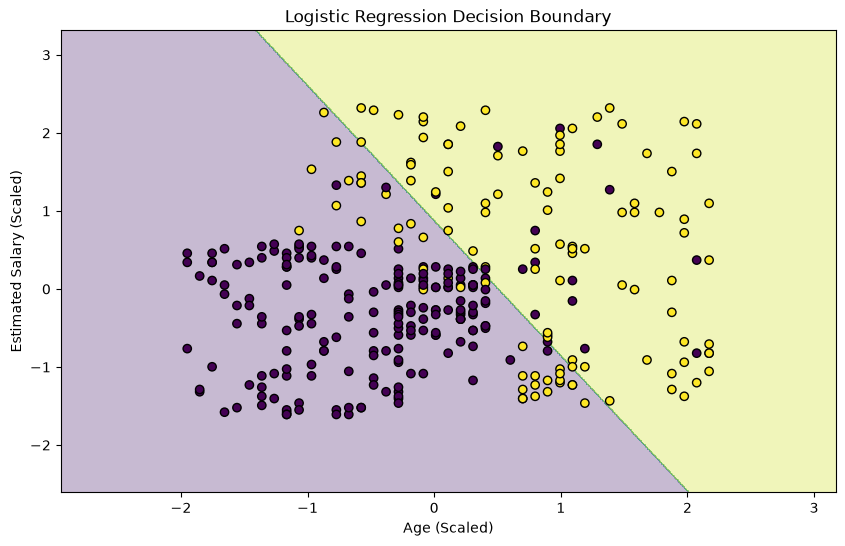

In [27]:
import numpy as np
import matplotlib.pyplot as plt

X_plot = X_train_scaled
y_plot = y_train.to_numpy()

x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.01),
    np.arange(y_min, y_max, 0.01)
)

Z = model.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))

plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(
    X_plot[:, 0],
    X_plot[:, 1],
    c=y_plot,
    edgecolor="black"
)

plt.xlabel("Age (Scaled)")
plt.ylabel("Estimated Salary (Scaled)")
plt.title("Logistic Regression Decision Boundary")

plt.show()

In [31]:
def predict_purchase(age, estimated_salary):
    customer = pd.DataFrame(
        [[age, estimated_salary]],
        columns=["Age", "EstimatedSalary"]
    )

    customer_scaled = scaler.transform(customer)

    prediction = model.predict(customer_scaled)
    probability = model.predict_proba(customer_scaled)

    if prediction[0] == 1:
        result = "Purchased"
    else:
        result = "Not Purchased"

    print("Prediction:", result)
    print("Probability:", probability[0])

In [32]:
predict_purchase(35, 80000)

Prediction: Not Purchased
Probability: [0.77344872 0.22655128]


In [33]:
predict_purchase(50, 120000)

Prediction: Purchased
Probability: [0.04810263 0.95189737]


In [34]:
predict_purchase(25, 30000)

Prediction: Not Purchased
Probability: [0.99189397 0.00810603]


In [35]:
predict_purchase(45, 100000)

Prediction: Purchased
Probability: [0.20413362 0.79586638]


In [36]:
import joblib

joblib.dump(model, "../models/logistic_regression_model.pkl")
joblib.dump(scaler, "../models/standard_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [37]:
loaded_model = joblib.load("../models/logistic_regression_model.pkl")
loaded_scaler = joblib.load("../models/standard_scaler.pkl")

print("Model loaded:", type(loaded_model))
print("Scaler loaded:", type(loaded_scaler))

Model loaded: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Scaler loaded: <class 'sklearn.preprocessing._data.StandardScaler'>


In [38]:
customer = pd.DataFrame(
    [[50, 120000]],
    columns=["Age", "EstimatedSalary"]
)

customer_scaled = loaded_scaler.transform(customer)

prediction = loaded_model.predict(customer_scaled)
probability = loaded_model.predict_proba(customer_scaled)

print("Prediction:", "Purchased" if prediction[0] == 1 else "Not Purchased")
print("Probability:", probability[0])

Prediction: Purchased
Probability: [0.04810263 0.95189737]


In [39]:
import joblib
from pathlib import Path

# Project root directory
BASE_DIR = Path.cwd().parent

# Models directory
MODELS_DIR = BASE_DIR / "models"

# Create models directory if it doesn't exist
MODELS_DIR.mkdir(exist_ok=True)

# Save trained Logistic Regression model
joblib.dump(
    model,
    MODELS_DIR / "logistic_regression_model.pkl"
)

# Save trained StandardScaler
joblib.dump(
    scaler,
    MODELS_DIR / "scaler.pkl"
)

print("Model and scaler saved successfully!")
print("Model:", MODELS_DIR / "logistic_regression_model.pkl")
print("Scaler:", MODELS_DIR / "scaler.pkl")

Model and scaler saved successfully!
Model: d:\AIML projects\advertisement-sale-prediction\models\logistic_regression_model.pkl
Scaler: d:\AIML projects\advertisement-sale-prediction\models\scaler.pkl
